0. Data Loading & Quality Checks

1. EDA & Temporal Splitting

2. Baseline Models & RTE Benchmark
   - Naive Forecast (48h)
   - Seasonal Naive (168h)
   - RTE D+1 Benchmark
   - MAE / RMSE Comparison

3. Statistical Models
   - Box-Jenkins
   - ARIMA / SARIMA
   - SARIMAX
   - Holt-Winters

4. Machine Learning
   - Feature Engineering
   - LightGBM
   - Walk-forward Validation

5. Deep Learning (optional)

6. Final Evaluation
   - Comparison with RTE and Baselines
   - MAE / RMSE
   - Forecast Uncertainty
   - Peak-hour Analysis
   - Business Recommendations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

---
# **0. Data Loading & Quality Checks**


In [2]:
df = pd.read_csv("france_electricity_hourly.csv")

print("Shape:", df.shape)
display(df.head())
display(df.info())

Shape: (65710, 4)


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+0000,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+0000,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+0000,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+0000,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+0000,52972.0,52188.0,5.72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65710 entries, 0 to 65709
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime_utc        65710 non-null  object 
 1   load_mw             65703 non-null  float64
 2   rte_forecast_d1_mw  65703 non-null  float64
 3   temperature_c       65710 non-null  float64
dtypes: float64(3), object(1)
memory usage: 2.0+ MB


None

---
### **0.1 — Temporal Integrity & Missing Values**

We convert timestamps to UTC and check temporal consistency.

Results:

65,710 hourly observations (2019–June 2026).

No duplicated or missing timestamps.

7 missing values in both load_mw and rte_forecast_d1_mw, occurring during October daylight saving transitions.

Time zone strategy:

UTC: regular hourly spacing for time-series models and lags.

Europe/Paris: calendar features, forecasting deadline (before 12:00), and target hours (D+1).

In [3]:
# Convert datetime and set temporal index
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True)

df = df.set_index("datetime_utc").sort_index()
# Temporal audit
print("Start:", df.index.min())
print("End:", df.index.max())
print("Duplicated timestamps:", df.index.duplicated().sum())

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h",
    tz="UTC"
)

print("Expected hours:", len(expected_index))
print("Actual rows:", len(df))
print("Missing timestamps:", len(expected_index.difference(df.index)))

# Missing values
print("\nMissing values per column:")
print(df.isna().sum())

# Rows containing missing values
display(df[df.isna().any(axis=1)])

Start: 2019-01-01 00:00:00+00:00
End: 2026-06-30 21:00:00+00:00
Duplicated timestamps: 0
Expected hours: 65710
Actual rows: 65710
Missing timestamps: 0

Missing values per column:
load_mw               7
rte_forecast_d1_mw    7
temperature_c         0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2019-10-27 00:00:00+00:00,NaN,NaN,15.13
2020-10-25 00:00:00+00:00,NaN,NaN,13.64
2021-10-31 00:00:00+00:00,NaN,NaN,11.86
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2023-10-29 00:00:00+00:00,NaN,NaN,14.41
2024-10-27 00:00:00+00:00,NaN,NaN,12.97
2025-10-26 00:00:00+00:00,NaN,NaN,8.86


In [4]:
idx = df.index.get_loc("2022-10-30 00:00:00+00:00	")

display(df.iloc[idx-2:idx+3])

,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2022-10-29 22:00:00+00:00,39868.0,37338.0,15.46
2022-10-29 23:00:00+00:00,36837.0,34175.0,14.85
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2022-10-30 01:00:00+00:00,36126.0,31100.0,14.72
2022-10-30 02:00:00+00:00,31669.0,30612.0,13.97


---
### **0.2 — Missing Value Treatment & Descriptive Statistics**

We apply time-based linear interpolation to the 7 missing observations to preserve a continuous hourly series.

Save original observations in df_raw.

Interpolate load_mw and rte_forecast_d1_mw.

Exclude originally missing observations from final evaluation.

Inspect descriptive statistics for potential anomalies.

No future information is allowed when generating day-ahead forecasts.

In [5]:
# Preserve original data
df_raw = df.copy()

# Interpolate missing values
cols = ["load_mw", "rte_forecast_d1_mw"]
df[cols] = df[cols].interpolate(method="time")

# French local time for calendar and forecasting logic
df["datetime_fr"] = df.index.tz_convert("Europe/Paris")

# Verify interpolation and inspect descriptive statistics
print(df[cols].isna().sum())
display(df[["load_mw", "rte_forecast_d1_mw", "temperature_c"]].describe())

load_mw               0
rte_forecast_d1_mw    0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
count,65710.000000,65710.000000,65710.000000
mean,51497.351514,50830.222143,13.071639
std,11018.880178,11048.384887,7.022981
min,29364.000000,27712.000000,-5.090000
25%,43320.000000,42588.000000,7.920000
50%,49767.000000,48962.000000,12.500000
75%,58746.000000,58062.000000,17.980000
max,90210.000000,89975.000000,38.520000


In [6]:
idx = df.index.get_loc("2019-10-27 00:00:00+00:00")

display(df.iloc[idx-1:idx+2])

,load_mw,rte_forecast_d1_mw,temperature_c,datetime_fr
datetime_utc,,,,
2019-10-26 23:00:00+00:00,42172.0,40425.0,15.13,2019-10-27 01:00:00+02:00
2019-10-27 00:00:00+00:00,40558.5,38562.5,15.13,2019-10-27 02:00:00+02:00
2019-10-27 01:00:00+00:00,38945.0,36700.0,14.26,2019-10-27 02:00:00+01:00


--- 
# **1. EDA & Temporal Splitting**


### **1.0 Temporal Splitting**

In [7]:
local = df["datetime_fr"]

train = df.loc[local < pd.Timestamp("2025-01-01", tz="Europe/Paris")].copy()

val = df.loc[
    (local >= pd.Timestamp("2025-01-01", tz="Europe/Paris")) &
    (local < pd.Timestamp("2026-01-01", tz="Europe/Paris"))
].copy()

test = df.loc[
    local >= pd.Timestamp("2026-01-01", tz="Europe/Paris")
].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (52607, 4)
Validation: (8760, 4)
Test: (4343, 4)


### **1.1 — Exploratory Data Analysis**

We explore the hourly electricity consumption to identify long-term trends, seasonal patterns, and potential anomalies before modeling.

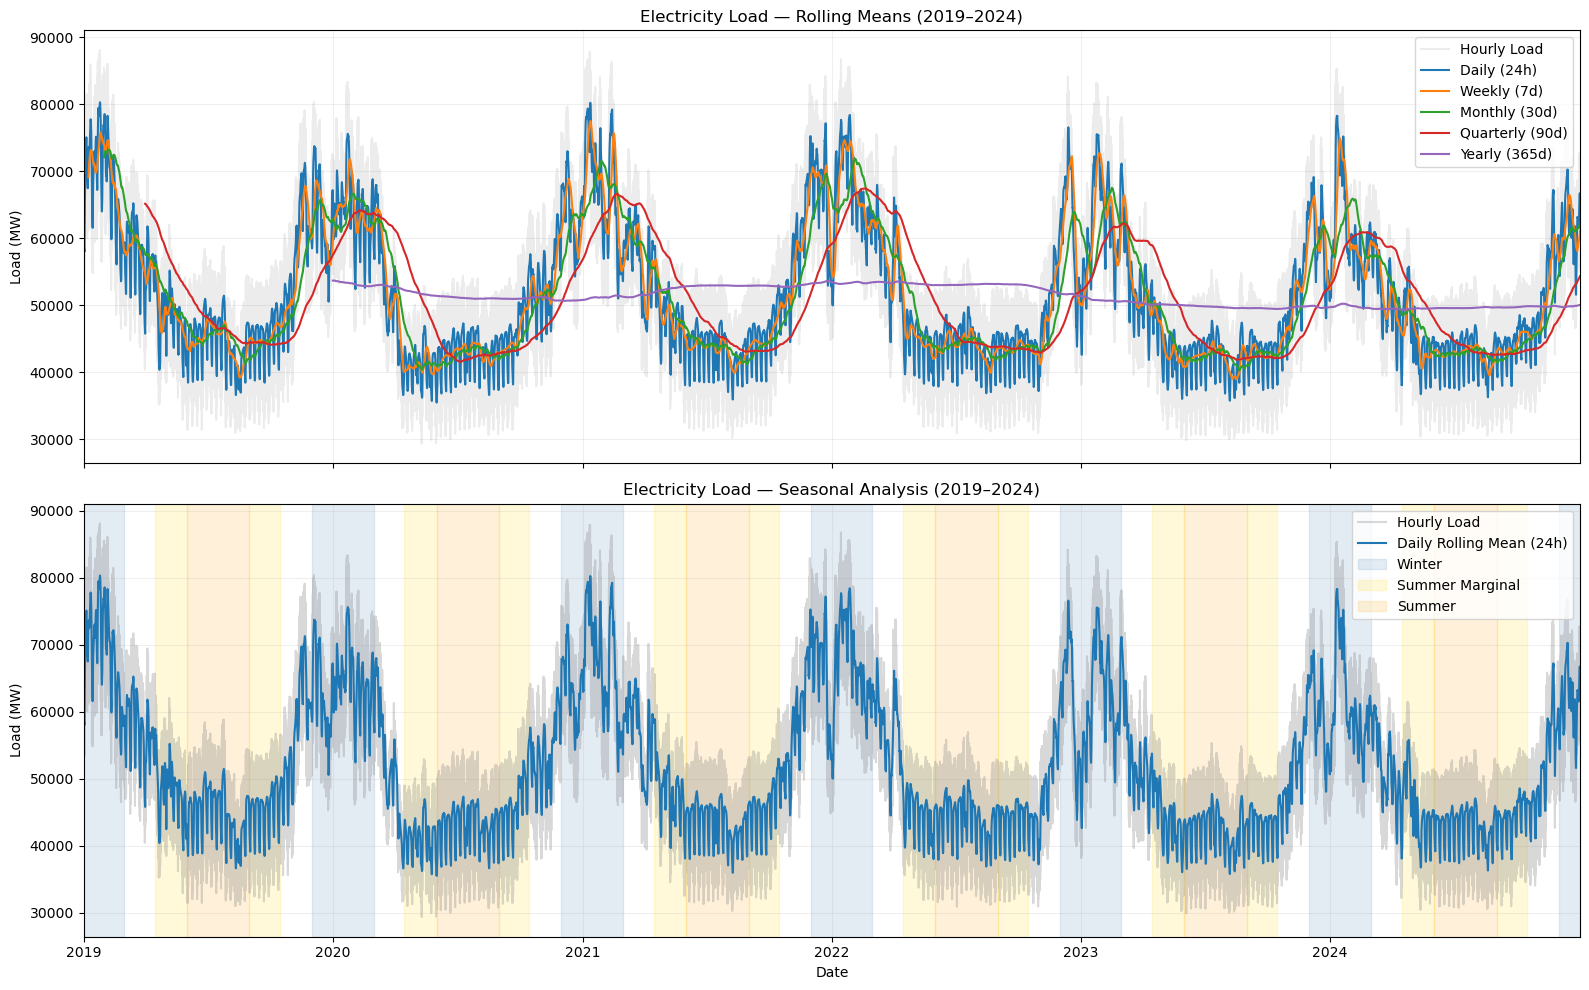

In [8]:
y = train["load_mw"]

windows = {
    "Daily (24h)": 24,
    "Weekly (7d)": 24 * 7,
    "Monthly (30d)": 24 * 30,
    "Quarterly (90d)": 24 * 90,
    "Yearly (365d)": 24 * 365
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# GRAPH 1 — Rolling means
ax = axes[0]

ax.plot(y.index, y, alpha=0.15, color="gray", label="Hourly Load")

for label, window in windows.items():
    ax.plot(
        y.index,
        y.rolling(window).mean(),
        label=label,
        linewidth=1.5
    )

ax.set_title("Electricity Load — Rolling Means (2019–2024)")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)


# GRAPH 2 — Seasonal analysis
ax = axes[1]

ax.plot(y.index, y, alpha=0.3, color="gray", label="Hourly Load")

ax.plot(
    y.index,
    y.rolling(24).mean(),
    linewidth=1.5,
    label="Daily Rolling Mean (24h)"
)

start_year = train["datetime_fr"].dt.year.min()
end_year = train["datetime_fr"].dt.year.max()

added_labels = set()

for year in range(start_year, end_year + 2):

    seasons = [
        ("Winter", f"{year-1}-12-01", f"{year}-03-01", "steelblue"),
        ("Summer Marginal", f"{year}-04-15", f"{year}-06-01", "gold"),
        ("Summer", f"{year}-06-01", f"{year}-09-01", "orange"),
        ("Summer Marginal", f"{year}-09-01", f"{year}-10-15", "gold"),
    ]

    for season, start, end, color in seasons:

        # Convert French local dates to UTC
        start = pd.Timestamp(start, tz="Europe/Paris").tz_convert("UTC")
        end = pd.Timestamp(end, tz="Europe/Paris").tz_convert("UTC")

        # Avoid duplicate labels
        label = season if season not in added_labels else None

        ax.axvspan(
            start,
            end,
            color=color,
            alpha=0.15,
            label=label
        )

        added_labels.add(season)

ax.set_xlim(y.index.min(), y.index.max())
ax.set_title("Electricity Load — Seasonal Analysis (2019–2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Comments :** 


-Significant short-term variability: hourly fluctuations are progressively smoothed by larger rolling windows, revealing the underlying seasonal structure.

- Relatively stable long-term level: the yearly rolling mean shows no strong sustained trend, despite some interannual variations.

- Strong annual seasonality: electricity demand peaks during winter, likely driven by heating needs, while summer exhibits significantly lower consumption.
- Refined seasonal interpretation: France's temperate climate suggests that the traditional winter/summer classification may be too simplistic. During late spring and early autumn, temperatures are often mild enough to limit residential heating demand. These Summer Marginal periods appear to share relatively low consumption levels with summer.

This motivates investigating more refined seasonal indicators rather than relying exclusively on calendar seasons.

### **Weekly Analysis**

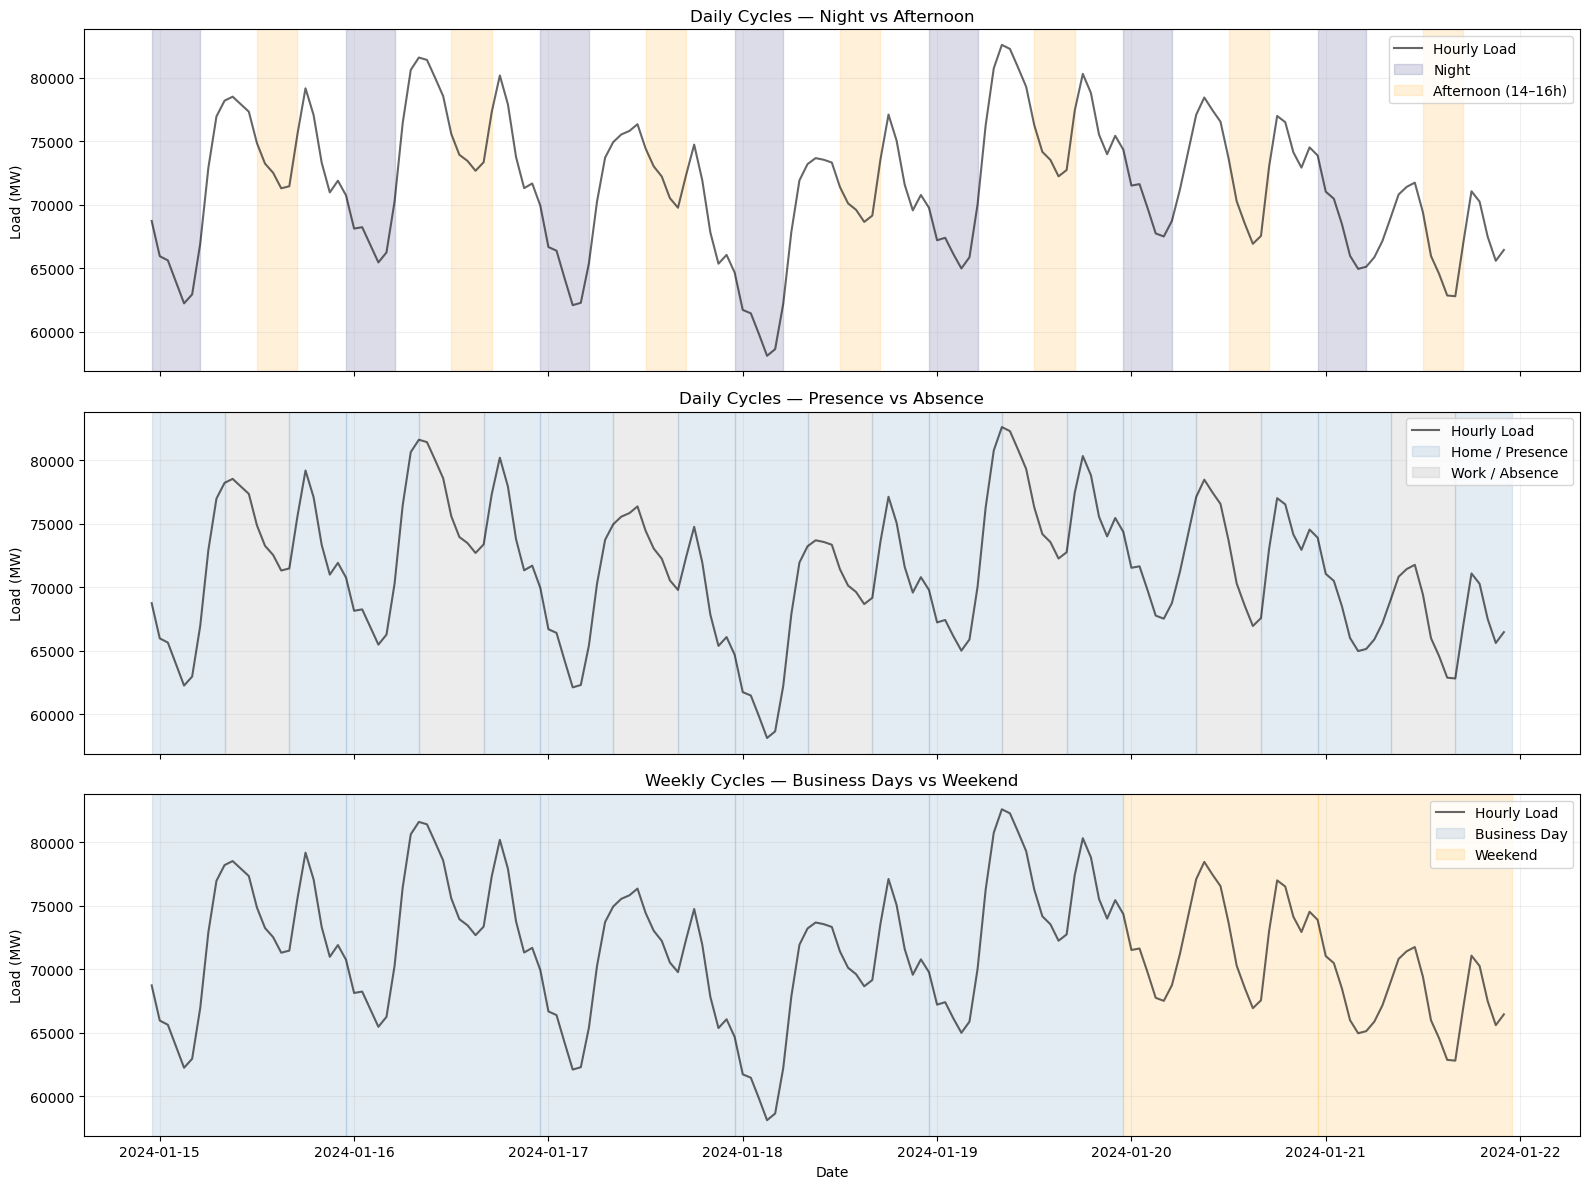

In [9]:
# One week from training data (French local dates)
local = train["datetime_fr"]
week = train.loc[
    (local >= pd.Timestamp("2024-01-15", tz="Europe/Paris")) &
    (local < pd.Timestamp("2024-01-22", tz="Europe/Paris")),
    "load_mw"
]

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax in axes:
    ax.plot(week.index, week, color="black", alpha=0.6, label="Hourly Load")
    ax.set_ylabel("Load (MW)")
    ax.grid(alpha=0.2)

# French local time periods
days = pd.date_range("2024-01-15", periods=7, freq="D", tz="Europe/Paris")

def shade(ax, day, start, end, color, label):
    ax.axvspan(
        (day + pd.Timedelta(hours=start)).tz_convert("UTC"),
        (day + pd.Timedelta(hours=end)).tz_convert("UTC"),
        color=color, alpha=0.15, label=label
    )

for i, day in enumerate(days):

    # Plot 1 — Night and afternoon
    shade(axes[0], day, 0, 6, "midnightblue", "Night" if i == 0 else None)
    shade(axes[0], day, 13, 18, "orange", "Afternoon (14–16h)" if i == 0 else None)

    # Plot 2 — Presence and absence
    shade(axes[1], day, 0, 9, "steelblue", "Home / Presence" if i == 0 else None)
    shade(axes[1], day, 9, 17, "gray", "Work / Absence" if i == 0 else None)
    shade(axes[1], day, 17, 24, "steelblue", None)

    # Plot 3 — Business days vs weekend
    if day.dayofweek < 5:
        shade(axes[2], day, 0, 24, "steelblue",
              "Business Day" if i == 0 else None)
    else:
        shade(axes[2], day, 0, 24, "orange",
              "Weekend" if i == 5 else None)

titles = [
    "Daily Cycles — Night vs Afternoon",
    "Daily Cycles — Presence vs Absence",
    "Weekly Cycles — Business Days vs Weekend"
]

for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### **Comments**

- **Intraday seasonality:** zooming into a representative week reveals recurring consumption fluctuations, with nighttime troughs and morning/evening peaks. This motivates us to explore peak and off-peak hours, which can be found in the rate plans offered by our electricity providers

- **Presence vs. Activity:** Periods when households are presumed to be absent during business hours partially coincide with a decline in consumption. However, household presence alone does not allow for a clear distinction between peaks and troughs, particularly from evening to morning, when periods of activity and inactivity overlap. Activity-related indicators may therefore prove more relevant than simple presence indicators.

- **Weekdays vs. Weekends:** Based on our assumption regarding occupancy rates, weekends might suggest higher electricity consumption. Surprisingly, the graph shows an overall decline in national demand during weekends, prompting us to explore this widespread decline in the weekday/weekend breakdown. 


### **Quarterly Analysis — Hourly, Daily & Weekly**

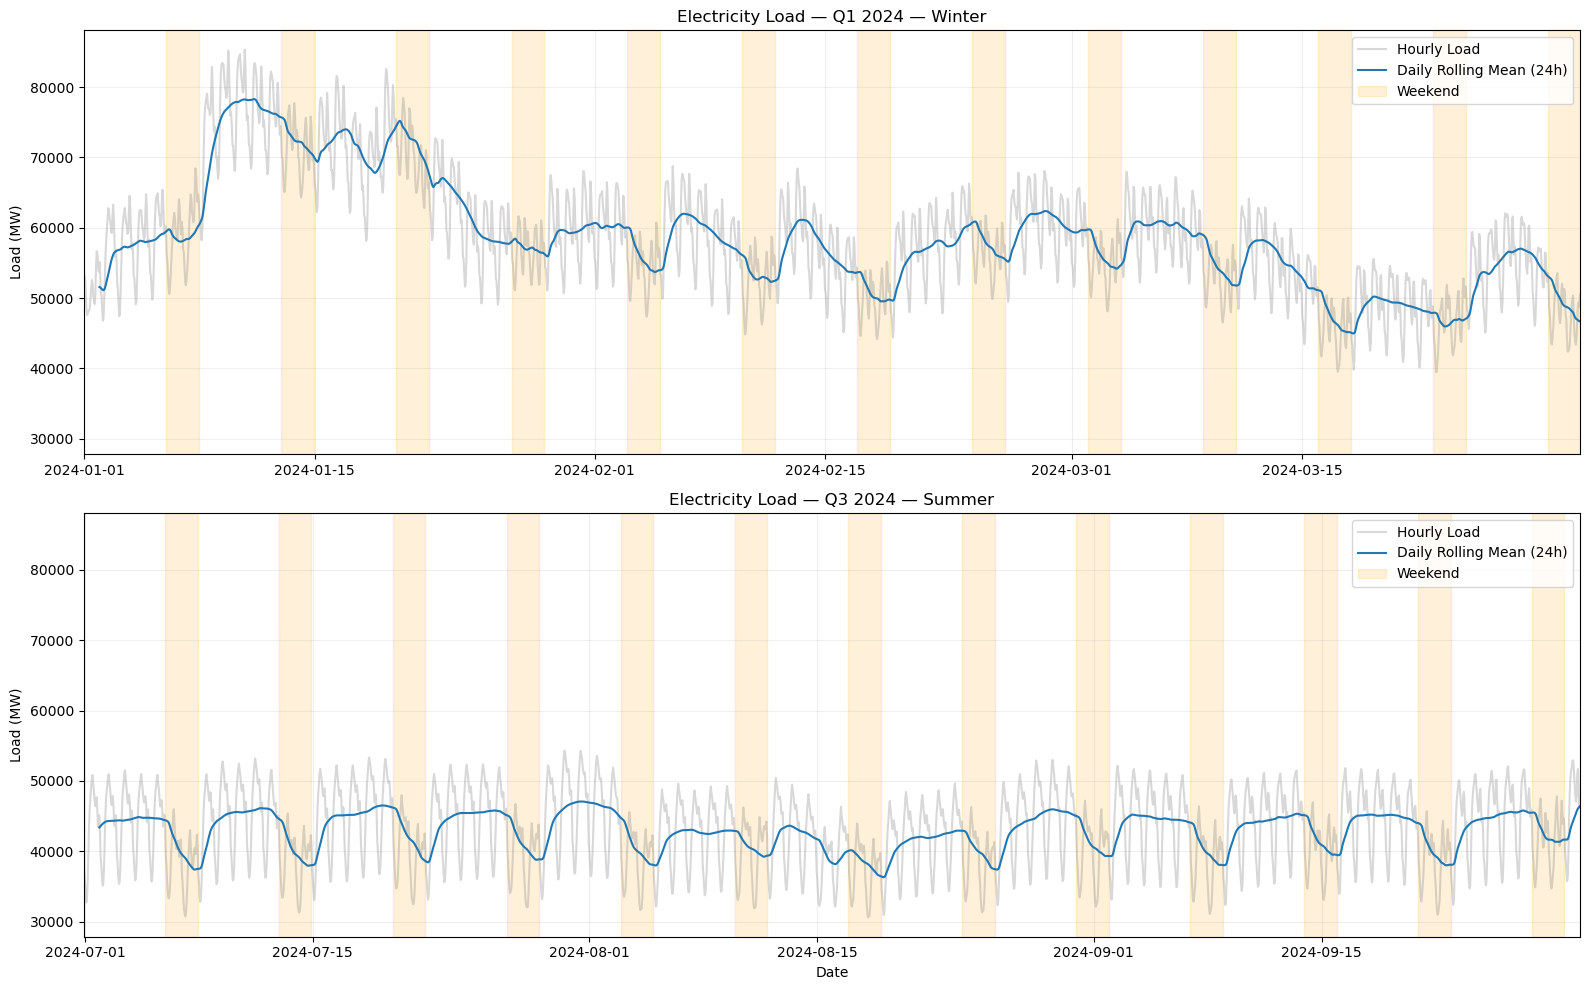

In [10]:
quarters = {
    "Q1 2024 — Winter": ("2024-01-01", "2024-04-01"),
    "Q3 2024 — Summer": ("2024-07-01", "2024-10-01")
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharey=True)

for ax, (label, (start, end)) in zip(axes, quarters.items()):

    # Select quarter using French local time
    local = train["datetime_fr"]

    quarter = train.loc[
        (local >= pd.Timestamp(start, tz="Europe/Paris")) &
        (local < pd.Timestamp(end, tz="Europe/Paris")),
        "load_mw"
    ]

    # Hourly load
    ax.plot(quarter.index, quarter, alpha=0.3,
            color="gray", label="Hourly Load")

    # Rolling means
    ax.plot(quarter.index, quarter.rolling(24).mean(),
            linewidth=1.5, label="Daily Rolling Mean (24h)")

    # Highlight weekends (French local time)
    local_days = pd.date_range(
        start, end, freq="D",
        tz="Europe/Paris", inclusive="left"
    )

    first_weekend = True

    for day in local_days:
        if day.dayofweek == 5:
            weekend_start = day.tz_convert("UTC")
            weekend_end = (day + pd.DateOffset(days=2)).tz_convert("UTC")

            ax.axvspan(
                weekend_start, weekend_end,
                color="orange", alpha=0.15,
                label="Weekend" if first_weekend else None
            )
            first_weekend = False

    ax.set_title(f"Electricity Load — {label}")
    ax.set_ylabel("Load (MW)")
    ax.set_xlim(quarter.index.min(), quarter.index.max())
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

### **Comments** 

- As can be seen in the two graphs, which show a weekday/weekend breakdown for Q1 and Q3, which are winter and summer quarters, respectively it is clear that the decline in consumption is widespread on weekends and that this is not an isolated case from our previous analysis, regardless of annual seasonality. 

- Therefore, national consumption clearly depends on two fundamental factors:

    **1) Economic activity:** The widespread decline is due to the sharp reduction in industrial and economic activity on weekends.

    **2) Individual household activity:** The volume of consumption accounted for by households in France is also a central factor in consumption, particularly when it comes to fine-grained patterns (intraday fluctuations). 

### **Consequently, within an annual cycle, which factor appears to have the greatest impact: a potential widespread decline in economic activity or widespread unemployment ?**

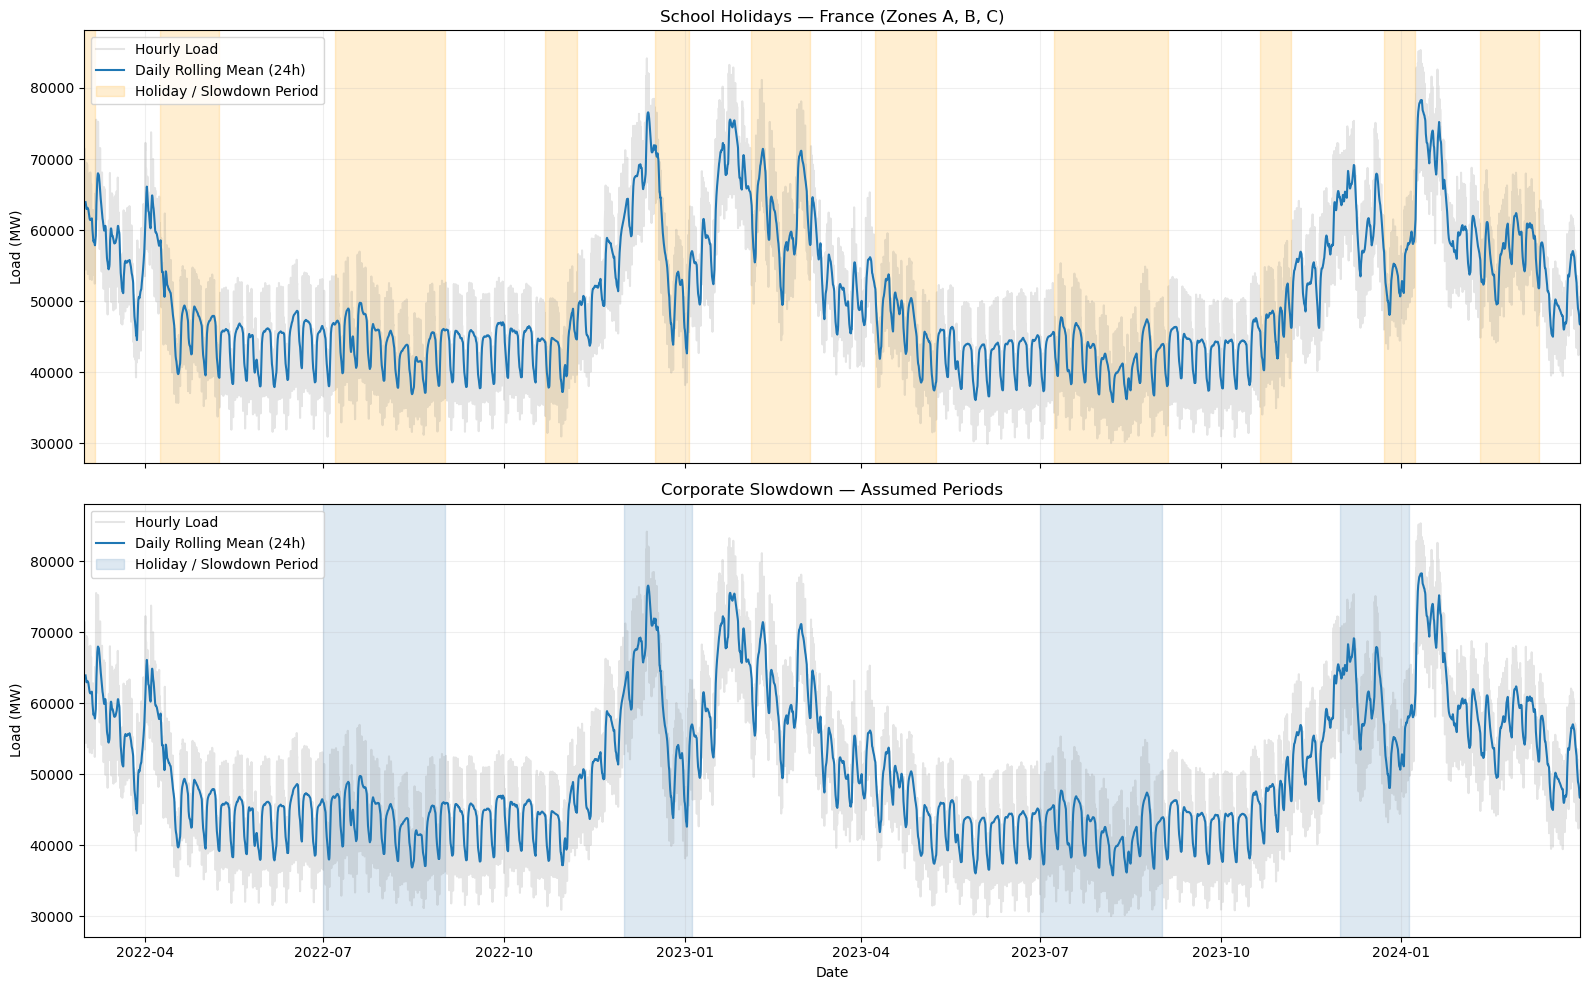

In [11]:
# Period: March 2022 to March 2024
start_date = "2022-03-01"
end_date = "2024-04-01"

start = pd.Timestamp(start_date, tz="Europe/Paris").tz_convert("UTC")
end = pd.Timestamp(end_date, tz="Europe/Paris").tz_convert("UTC")

y = train.loc[(train.index >= start) & (train.index < end), "load_mw"]

# School holidays: at least one zone (A, B, C)
school_holidays = [
    ("2022-03-01", "2022-03-07"),
    ("2022-04-09", "2022-05-09"),
    ("2022-07-07", "2022-09-01"),
    ("2022-10-22", "2022-11-07"),
    ("2022-12-17", "2023-01-03"),
    ("2023-02-04", "2023-03-06"),
    ("2023-04-08", "2023-05-09"),
    ("2023-07-08", "2023-09-04"),
    ("2023-10-21", "2023-11-06"),
    ("2023-12-23", "2024-01-08"),
    ("2024-02-10", "2024-03-11")
]

# Assumed corporate slowdown periods
corporate_holidays = [
    ("2022-07-01", "2022-09-01"),
    ("2022-12-01", "2023-01-05"),
    ("2023-07-01", "2023-09-01"),
    ("2023-12-01", "2024-01-05")
]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True, sharey=True)

studies = [
    ("School Holidays — France (Zones A, B, C)", school_holidays, "orange"),
    ("Corporate Slowdown — Assumed Periods", corporate_holidays, "steelblue")
]

for ax, (title, periods, color) in zip(axes, studies):

    # Hourly consumption
    ax.plot(y.index, y, color="gray", alpha=0.2, label="Hourly Load")

    # Daily rolling mean
    ax.plot(
        y.index,
        y.rolling(24).mean(),
        linewidth=1.5,
        label="Daily Rolling Mean (24h)"
    )

    # Highlight periods using French local dates
    for i, (date_start, date_end) in enumerate(periods):

        t0 = pd.Timestamp(date_start, tz="Europe/Paris").tz_convert("UTC")
        t1 = pd.Timestamp(date_end, tz="Europe/Paris").tz_convert("UTC")

        ax.axvspan(
            t0, t1,
            color=color,
            alpha=0.18,
            label="Holiday / Slowdown Period" if i == 0 else None
        )

    ax.set_title(title)
    ax.set_ylabel("Load (MW)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")
axes[-1].set_xlim(start, end)

plt.tight_layout()
plt.show()

### **Comment :**
- The business holiday chart seems to provide a much more accurate picture of the nationwide decline in consumption that naturally occurs around the winter holidays, which does not allow for a continued slowdown in activity as seen during the summer, a period that also typically sees a trough in July.

--- 
# **2. Baseline Models & RTE Benchmark**

### **2.1 — Forecasting Protocol**

All models follow the same operational forecasting procedure:

- **Forecast origin:** day D at 11:00 (Europe/Paris).
- **Target:** hourly electricity demand from 00:00 to 23:00 on D+1 (French local time).
- **Historical inputs:** observations available strictly before the forecast origin.
- **Time indexing:** UTC for hourly lags, French local time for target definition.
- **Output:** 24 hourly predictions per day.

**Daylight saving transitions:**
- 23-hour day: discard the prediction for the nonexistent 02:00.
- 25-hour day: assign NaN to the first 02:00 occurrence and keep the prediction for the second.

The same rules apply to every model and benchmark.

In [12]:
def get_forecast_window(target_day):

    # French local day D+1
    day = pd.Timestamp(target_day, tz="Europe/Paris")
    next_day = day + pd.DateOffset(days=1)

    # Forecast origin: day D at 11:00 local time
    origin = (day - pd.DateOffset(days=1)).replace(hour=11)

    # Real target timestamps in UTC
    target_hours = pd.date_range(
        start=day,
        end=next_day,
        freq="h",
        inclusive="left"
    ).tz_convert("UTC")

    return origin.tz_convert("UTC"), target_hours

**Test for origin and targeting**

In [13]:
for day in ["2025-01-15", "2025-03-30", "2025-06-26", "2025-10-26", "2025-11-26"]:
    origin, targets = get_forecast_window(day)

    print(
        day,
        "| Origin:", origin,
        "| Target hours:", len(targets)
    )

2025-01-15 | Origin: 2025-01-14 10:00:00+00:00 | Target hours: 24
2025-03-30 | Origin: 2025-03-29 10:00:00+00:00 | Target hours: 23
2025-06-26 | Origin: 2025-06-25 09:00:00+00:00 | Target hours: 24
2025-10-26 | Origin: 2025-10-25 09:00:00+00:00 | Target hours: 25
2025-11-26 | Origin: 2025-11-25 10:00:00+00:00 | Target hours: 24


### **2.2 — Daylight Saving Time Alignment**

Every model produces 24 predictions indexed by French clock hours (0–23).

We align these predictions with real UTC timestamps:

- Normal days: direct alignment.
- Spring transition: missing local hour excluded.
- Autumn transition: first repeated 02:00 assigned NaN.

DST transitions are known in advance, so this adjustment introduces no data leakage.

In [14]:
def align_24h_forecast(predictions, target_hours):

    predictions = np.asarray(predictions)

    if len(predictions) != 24:
        raise ValueError("Expected exactly 24 predictions")

    # French clock hours corresponding to real UTC timestamps
    local_hours = target_hours.tz_convert("Europe/Paris").hour

    # Map each clock hour to its prediction
    aligned = pd.Series(
        predictions[local_hours],
        index=target_hours,
        dtype=float
    )

    # Ignore first occurrence of repeated hours
    duplicate_mask = pd.Index(local_hours).duplicated(keep="last")
    aligned.iloc[np.flatnonzero(duplicate_mask)] = np.nan

    return aligned

for day in ["2025-01-15", "2025-03-30", "2025-10-26"]:

    _, targets = get_forecast_window(day)

    pred = align_24h_forecast(np.arange(24), targets)

    print(
        day,
        "| Predictions:", pred.notna().sum(),
        "| NaN:", pred.isna().sum()
    )

2025-01-15 | Predictions: 24 | NaN: 0
2025-03-30 | Predictions: 23 | NaN: 0
2025-10-26 | Predictions: 24 | NaN: 1


### **2.3 — Naive Forecasts & RTE Benchmark**

We establish three reference forecasts:

- **Naive (48h):** consumption observed 48 hours before the target timestamp.
- **Seasonal Naive (168h):** consumption observed 7 days before the target timestamp.
- **RTE D+1:** official day-ahead demand forecast.

Both naive methods use fixed UTC lags, respecting the 11:00 forecast cutoff.

Predictions are generated day by day using the same forecasting protocol. We initially evaluate them on the **2025 validation period**, keeping 2026 untouched.

In [18]:
baseline_days = []

# All French target dates in the validation set
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

for day in target_days:

    origin, targets = get_forecast_window(day)

    # One prediction per French clock hour (0–23)
    naive_48 = np.full(24, np.nan)
    naive_168 = np.full(24, np.nan)
    naive_720 = np.full(24, np.nan)
    naive_2160 = np.full(24, np.nan)
    rte_24 = np.full(24, np.nan)

    local_hours = targets.tz_convert("Europe/Paris").hour

    # Keep the second occurrence of repeated clock hours
    duplicates = pd.Index(local_hours).duplicated(keep="last")

    for t, hour, duplicate in zip(targets, local_hours, duplicates):

        if duplicate:
            continue

        # Fixed UTC lags
        t48 = t - pd.Timedelta(hours=48)
        t168 = t - pd.Timedelta(hours=168)
        t720 = t - pd.Timedelta(hours=720)
        t2160 = t - pd.Timedelta(hours=2160)

        # Verify forecast-time availability
        assert all(
            lag < origin
            for lag in [t48, t168, t720, t2160]
        )

        naive_48[hour] = df.loc[t48, "load_mw"]
        naive_168[hour] = df.loc[t168, "load_mw"]
        naive_720[hour] = df.loc[t720, "load_mw"]
        naive_2160[hour] = df.loc[t2160, "load_mw"]
        rte_24[hour] = df.loc[t, "rte_forecast_d1_mw"]

    # Align all forecasts with actual timestamps
    daily = pd.DataFrame({
        "actual": df.loc[targets, "load_mw"],
        "naive_48h": align_24h_forecast(naive_48, targets),
        "seasonal_naive_168h": align_24h_forecast(naive_168, targets),
        "monthly_naive_720h": align_24h_forecast(naive_720, targets),
        "quarterly_naive_2160h": align_24h_forecast(naive_2160, targets),
        "rte_d1": align_24h_forecast(rte_24, targets)
    })

    baseline_days.append(daily)

# Reconstruct the complete validation series
baseline_val = pd.concat(baseline_days).sort_index()

display(baseline_val.head())

,actual,naive_48h,seasonal_naive_168h,monthly_naive_720h,quarterly_naive_2160h,rte_d1
2024-12-31 23:00:00+00:00,64637.0,62862.0,56026.0,54322.0,42246.0,62988.0
2025-01-01 00:00:00+00:00,62362.0,59816.0,53536.0,51048.0,41066.0,61375.0
2025-01-01 01:00:00+00:00,61780.0,58802.0,52597.0,49953.0,39241.0,60062.0
2025-01-01 02:00:00+00:00,59824.0,56989.0,50093.0,48176.0,37714.0,56775.0
2025-01-01 03:00:00+00:00,57606.0,55544.0,47504.0,46752.0,38186.0,54550.0


### **2.4 — Evaluation Metrics & Missing Values**

**MAPE (%) is our primary metric** for model selection and hyperparameter tuning.

Since French national electricity demand is strictly positive and far from zero, MAPE provides an interpretable measure of relative forecasting error without denominator instability.

We also report MAE and RMSE for operational interpretation.

**Evaluation rules:**
- Exclude originally missing observations using `df_raw`.
- Exclude the first repeated 02:00 during autumn DST transitions.
- Never evaluate against interpolated ground truth.
- Use identical target timestamps for all models.

The 2026 test set remains reserved for final evaluation.

In [21]:
# Original observations only
valid_actual = df_raw.loc[baseline_val.index, "load_mw"].notna()
valid_rte = df_raw.loc[baseline_val.index, "rte_forecast_d1_mw"].notna()

# Exclude missing original observations
evaluation_mask = valid_actual & valid_rte

baseline_eval = baseline_val.loc[evaluation_mask].copy()

# Exclude DST-related NaNs before evaluation
baseline_eval = baseline_eval.dropna()

# Check missing predictions
print(baseline_eval.isna().sum())

# Missing model predictions must be investigated, not silently dropped
assert baseline_eval.notna().all().all()
assert (baseline_eval["actual"] > 0).all()

print("Evaluated hours:", len(baseline_eval))

actual                   0
naive_48h                0
seasonal_naive_168h      0
monthly_naive_720h       0
quarterly_naive_2160h    0
rte_d1                   0
dtype: int64
Evaluated hours: 8759


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "MAE (MW)": mean_absolute_error(y_true, y_pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_true, y_pred))
    }

models = [
    "naive_48h",
    "seasonal_naive_168h",
    "monthly_naive_720h",
    "quarterly_naive_2160h",
    "rte_d1"
]
results = {}


for model in models:
    results[model] = evaluate_forecast(
        baseline_eval["actual"],
        baseline_eval[model]
    )

baseline_results = pd.DataFrame(results).T

display(baseline_results.sort_values("MAPE (%)").round(2))

,MAPE (%),MAE (MW),RMSE (MW)
rte_d1,2.82,1396.65,1725.79
seasonal_naive_168h,6.43,3460.56,5145.81
naive_48h,8.04,3993.71,5219.24
monthly_naive_720h,12.70,6436.92,8306.45
quarterly_naive_2160h,22.20,11233.58,14317.34


---
# **3. Statistical Models**
### **3.1 Box-Jenkins (1)— Plot & Seasonal Decomposition**
Following the Box-Jenkins methodology, we first examine the structural components of electricity demand using STL (Seasonal-Trend decomposition using LOESS).

We decompose the hourly training series into trend, daily seasonality (24h), and residuals.

The objective is to determine whether the daily seasonal component captures the main fluctuations or whether additional temporal patterns remain unexplained.

**STL Decomposition (24h)**

We apply STL to the hourly electricity demand from 2022 to 2024, using a daily seasonal period of 168 hours.

We try to observe how these components evolve over multiple years


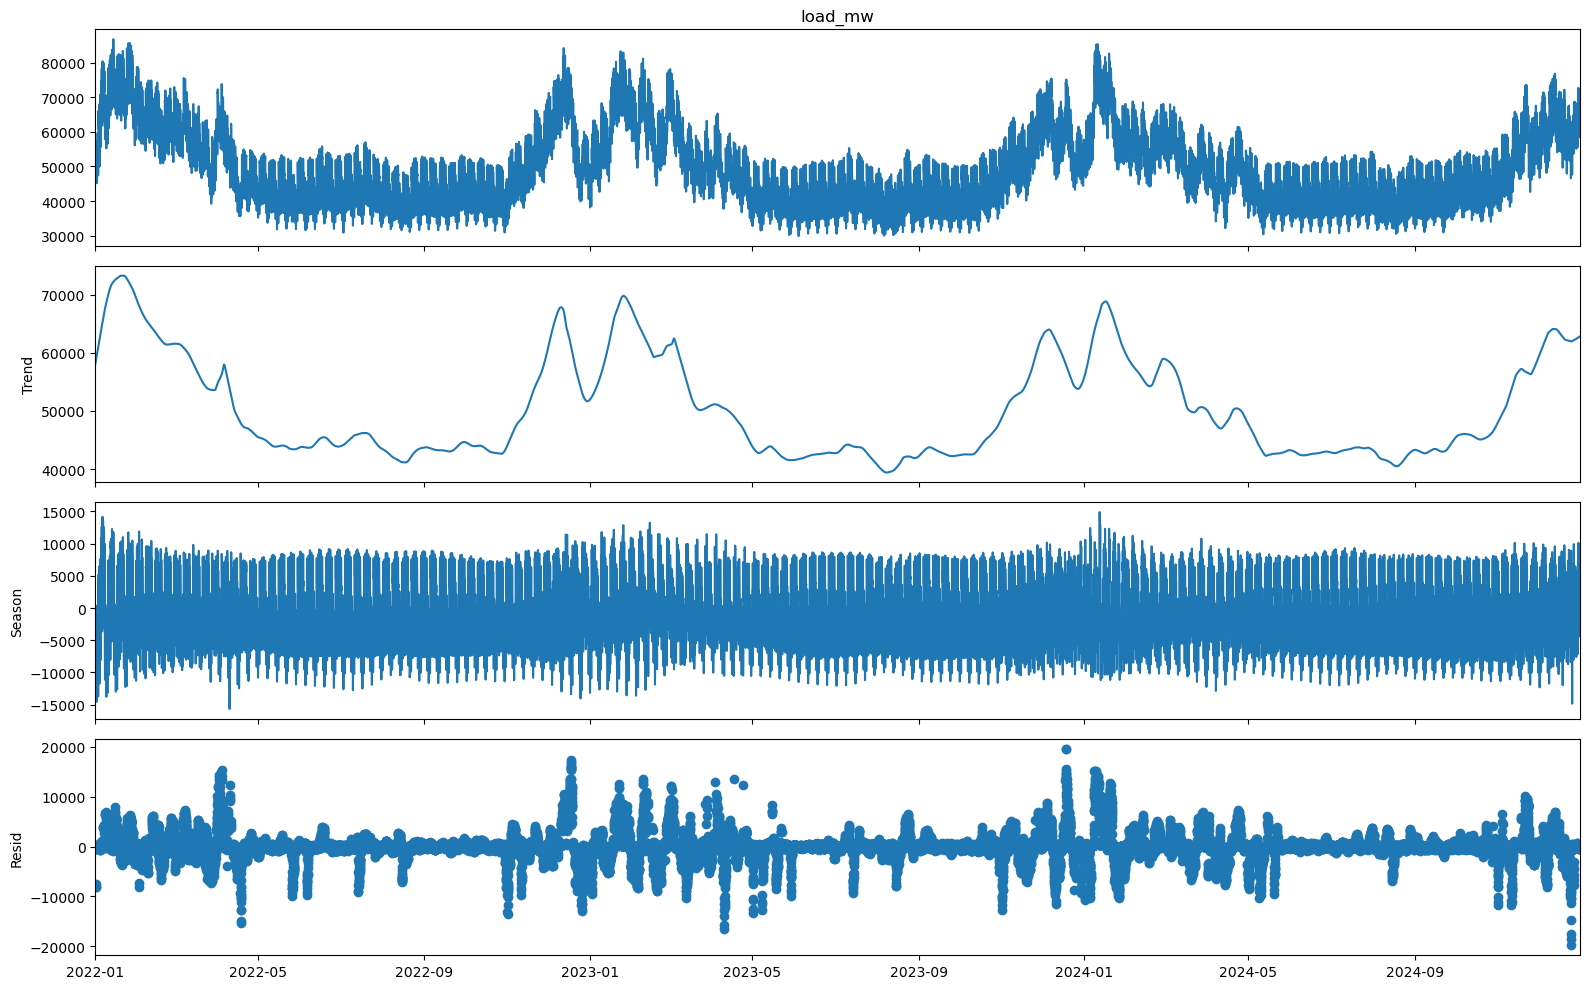

In [26]:
from statsmodels.tsa.seasonal import STL, MSTL

# Select 2022–2024 from training data
y_stl = train.loc["2022-01-01":"2024-12-31", "load_mw"]

# STL decomposition — daily seasonality
stl = STL(y_stl, period=168, robust=True).fit()

# Plot components
fig = stl.plot()
fig.set_size_inches(16, 10)
plt.tight_layout()
plt.show()

**MSTL Decomposition (24h, 168h)**

Daily seasonality (24h): recurring intraday patterns.

Weekly seasonality (168h): recurring weekly consumption patterns.

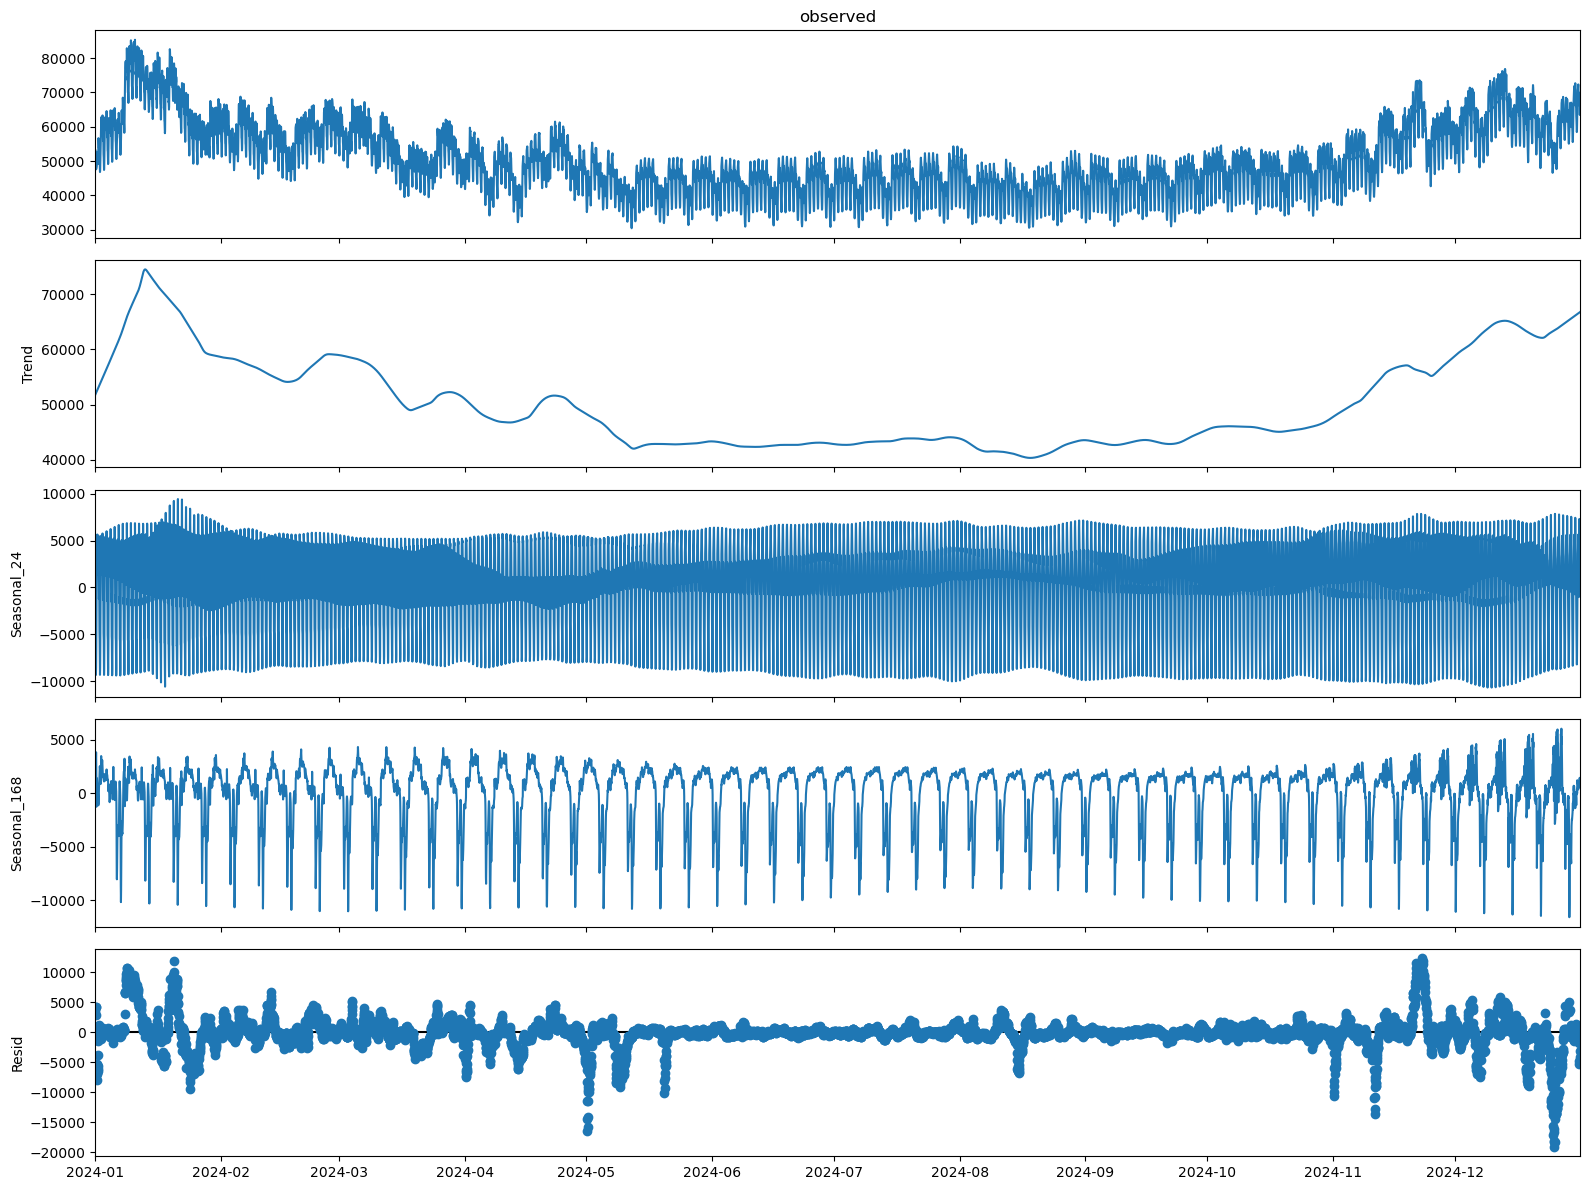

In [29]:
# Select 2024
y_mstl = train.loc["2024-01-01":"2024-12-31", "load_mw"]

# Multiple seasonal decomposition
mstl = MSTL(
    y_mstl,
    periods=(24, 168),
    stl_kwargs={"robust": True}
).fit()

# Plot components
fig = mstl.plot()
fig.set_size_inches(16, 12)
plt.tight_layout()
plt.show()

**Seasonal Comparison**
We compare the daily and weekly seasonal components extracted by MSTL across four representative months of 2024:

- Winter: January
- Spring: April
- Summer: July
- Autumn: October

The objective is to investigate whether the amplitude and variability of daily and weekly consumption patterns change across seasons.

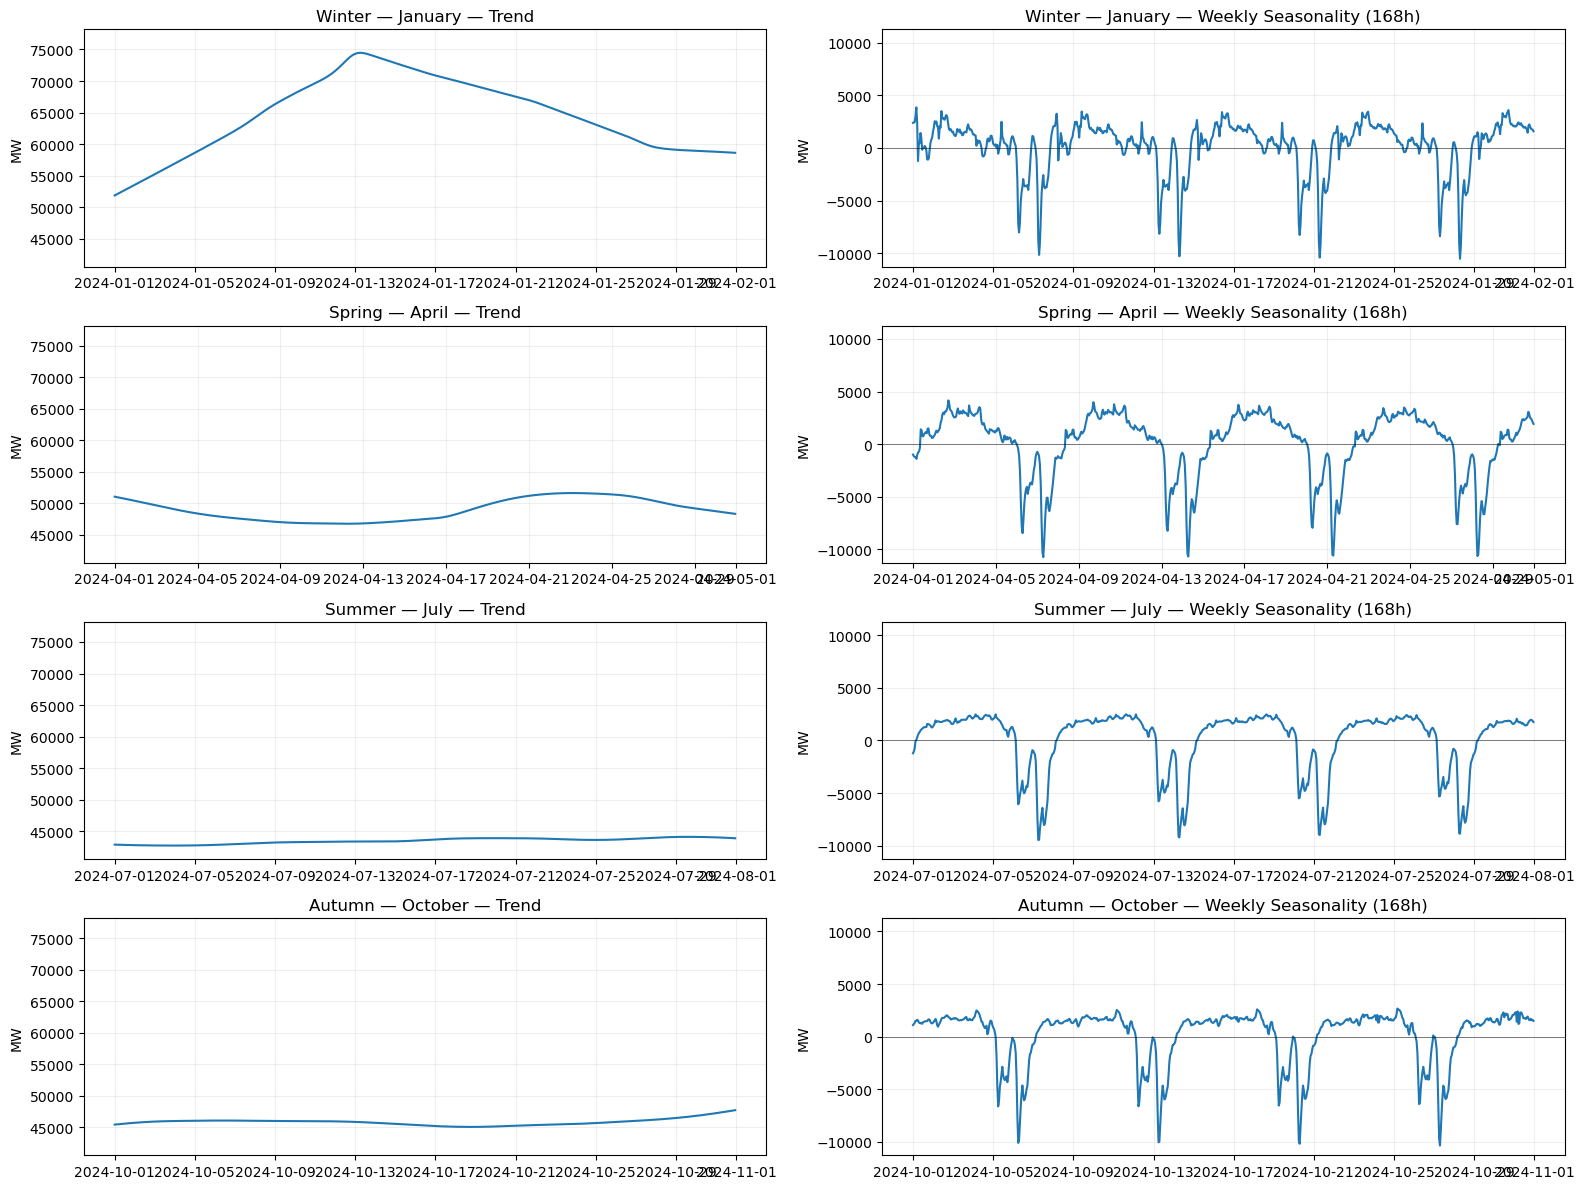

In [35]:
months = {
    "Winter — January": "2024-01",
    "Spring — April": "2024-04",
    "Summer — July": "2024-07",
    "Autumn — October": "2024-10"
}

fig, axes = plt.subplots(4, 2, figsize=(16, 12))

for i, (season, month) in enumerate(months.items()):

    # Trend
    trend = mstl.trend.loc[month]
    axes[i, 0].plot(trend.index, trend.values)
    axes[i, 0].set_title(f"{season} — Trend")
    axes[i, 0].set_ylabel("MW")
    axes[i, 0].grid(alpha=0.2)

    # Weekly seasonality
    weekly = mstl.seasonal["seasonal_168"].loc[month]
    axes[i, 1].plot(weekly.index, weekly.values)
    axes[i, 1].set_title(f"{season} — Weekly Seasonality (168h)")
    axes[i, 1].set_ylabel("MW")
    axes[i, 1].grid(alpha=0.2)

# Common Y-axis for each column
trend_min = min(mstl.trend.loc[m].min() for m in months.values())
trend_max = max(mstl.trend.loc[m].max() for m in months.values())

weekly_max = max(
    mstl.seasonal["seasonal_168"].loc[m].abs().max()
    for m in months.values()
)

for i in range(4):
    axes[i, 0].set_ylim(trend_min * 0.95, trend_max * 1.05)
    axes[i, 1].set_ylim(-weekly_max * 1.05, weekly_max * 1.05)
    axes[i, 1].axhline(0, color="black", linewidth=0.7, alpha=0.5)

plt.tight_layout()
plt.show()

**Quantifying Seasonal Amplitude**

In [31]:
seasonal_stats = []

for season, month in months.items():

    daily = mstl.seasonal["seasonal_24"].loc[month]
    weekly = mstl.seasonal["seasonal_168"].loc[month]

    seasonal_stats.append({
        "Season": season,
        "Daily Std (MW)": daily.std(),
        "Weekly Std (MW)": weekly.std(),
        "Daily Range (MW)": daily.max() - daily.min(),
        "Weekly Range (MW)": weekly.max() - weekly.min()
    })

seasonal_stats = pd.DataFrame(seasonal_stats).set_index("Season")

display(seasonal_stats.round(2))

,Daily Std (MW),Weekly Std (MW),Daily Range (MW),Weekly Range (MW)
Season,,,,
Winter — January,4794.40,2510.56,20033.73,14382.64
Spring — April,4056.27,3086.40,14453.59,14888.09
Summer — July,5170.29,2860.38,17144.77,11928.93
Autumn — October,4946.92,2602.47,16519.01,13013.36


### **3.2 Box-Jenkins (2) - Transform**

we need to assess whether the electricity demand series is stationary.


A stationary time series has statistical properties, such as its mean, variance and autocovariance structure, that do not change over time.
We apply two complementary statistical tests:
- Augmented Dickey-Fuller (ADF) Test :

    H₀: The series has a unit root (non-stationary).

    H₁: The series has no unit root (stationary under the test assumptions).

    Desired result: p-value < 0.05, allowing us to reject H₀.

In [41]:
from statsmodels.tsa.stattools import adfuller, kpss

# Select 2024 training observations
y = train.loc["2022-01-01":"2022-12-31", "load_mw"].dropna()
# y = train["load_mw"].dropna()
# ADF test
adf_result = adfuller(y, autolag="AIC")

print("Augmented Dickey-Fuller Test")
print(f"Statistic: {adf_result[0]:.4f}")
print(f"p-value:   {adf_result[1]:.4f}")


Augmented Dickey-Fuller Test
Statistic: -3.5969
p-value:   0.0058


- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test

    H₀: The series is stationary around a constant level (regression="c").

    H₁: The series is not level-stationary.

    Desired result: p-value > 0.05, meaning we do not reject H₀.

Combining both tests provides complementary evidence about stationarity. However, neither test alone guarantees that the series is stationary, particularly in the presence of complex seasonal patterns.

In [43]:

# KPSS test
kpss_result = kpss(y, regression="c", nlags="auto")

print("\nKPSS Test")
print(f"Statistic: {kpss_result[0]:.4f}")
print(f"p-value:   {kpss_result[1]:.4f}")


KPSS Test
Statistic: 5.0507
p-value:   0.0100


/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_92441/3966449262.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


**Differencing**

Malheuresuement le test KPSS ne confirme pas du tout une série stationnaire 